In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler

In [114]:
# Inject DataSet

df=pd.read_csv(r"C:\Users\hp\Downloads\car_fuel_efficiency_2026.csv")

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


In [116]:
df=df[['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight', 'fuel_efficiency_mpg']]

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   engine_displacement  10000 non-null  int64  
 2   horsepower           9123 non-null   float64
 3   vehicle_weight       10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


EDA

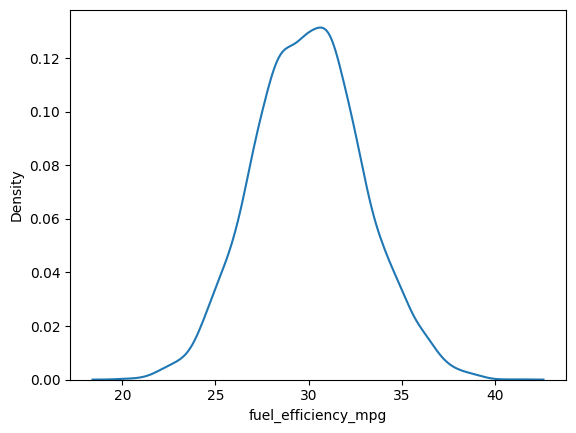

In [118]:
sns.kdeplot(df['fuel_efficiency_mpg'])
plt.show()

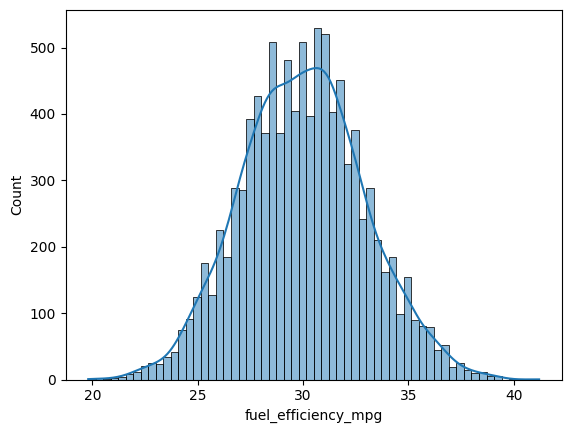

In [119]:
sns.histplot(df['fuel_efficiency_mpg'], kde=True)
plt.show()

Question - 1 There's one column with missing values. What is it?

In [120]:
df.isnull().sum()

model_year               0
engine_displacement      0
horsepower             877
vehicle_weight           0
fuel_efficiency_mpg      0
dtype: int64

Question - 2 What's the median (50% percentile) for variable 'horsepower'?

In [121]:
df['horsepower'].median()

np.float64(254.0)

Splitting DataSet into Train, Validation and Test Set

In [122]:
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test

np.random.seed(42)
idx=np.arange(n)
np.random.shuffle(idx)

df_train=df.iloc[idx[:n_train]]
df_val=df.iloc[idx[n_train:n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val:]]

Question - 3                                                                    
1. We need to deal with missing values for the column from Q1.                                                  
2. We have two options: fill it with 0 or with the mean of this variable.                                           
3. Try both options. For each, train a linear regression model without regularization using the code from the lessons.       
4. For computing the mean, use the training only!                                               
5. Use the validation dataset to evaluate the models and compare the RMSE of each option.                               
6. Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.                                                                                       
7. Which option gives better RMSE?

In [123]:
# Creating Copies
df_train_copy=df_train
df_val_copy=df_val
df_test_copy=df_test

# Option 1 : Filling with mean
mean=df_train_copy['horsepower'].mean()
df_train_copy['horsepower']=df_train_copy['horsepower'].fillna(mean)
df_val_copy['horsepower']=df_val_copy['horsepower'].fillna(mean)
df_test_copy['horsepower']=df_test_copy['horsepower'].fillna(mean)

# Traning LinearRegression model
lr=LinearRegression()
lr.fit(df_train_copy.drop('fuel_efficiency_mpg', axis=1), df_train_copy['fuel_efficiency_mpg'])

# Predictions
y_pred=lr.predict(df_val_copy.drop('fuel_efficiency_mpg', axis=1))

# Evaluating
print("RMSE for Option 1 : ", np.round(root_mean_squared_error(df_val_copy['fuel_efficiency_mpg'], y_pred), 3))

RMSE for Option 1 :  2.202


In [124]:
# Option 2 : Filling with Zero
df_train['horsepower']=df_train['horsepower'].fillna(0)
df_val['horsepower']=df_val['horsepower'].fillna(0)
df_test['horsepower']=df_test['horsepower'].fillna(0)

# Traning LinearRegression model
lr=LinearRegression()
lr.fit(df_train.drop('fuel_efficiency_mpg', axis=1), df_train['fuel_efficiency_mpg'])

# Predictions
y_pred=lr.predict(df_val.drop('fuel_efficiency_mpg', axis=1))

# Evaluating
print("RMSE for Option 1 : ", np.round(root_mean_squared_error(df_val['fuel_efficiency_mpg'], y_pred), 3))

RMSE for Option 1 :  2.202


Question - 4                                                                            
1. Now let's train a regularized linear regression.                                                                 
2. For this question, fill the NAs with 0.                                                                          
3. Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].                                             
4. Use RMSE to evaluate the model on the validation dataset.                                            
5. Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.                                                       
6. Which r gives the best RMSE?                                                     
If multiple options give the same best RMSE, select the smallest r.                                                 

In [125]:
X_train = df_train.drop('fuel_efficiency_mpg', axis=1)
y_train = df_train['fuel_efficiency_mpg']
X_val = df_val.drop('fuel_efficiency_mpg', axis=1)
y_val = df_val['fuel_efficiency_mpg']
std=StandardScaler()
df_train_scaled=std.fit_transform(X_train)
df_val_scaled=std.transform(X_val)
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    lr1=Ridge(alpha=r)
    lr1.fit(df_train_scaled, y_train)
    y_pred=lr1.predict(df_val_scaled)
    error=np.round(root_mean_squared_error(y_val, y_pred), 4)
    print(f"alpha: {r} -->  RMSE: {error}")


alpha: 0 -->  RMSE: 2.2018
alpha: 0.01 -->  RMSE: 2.2018
alpha: 0.1 -->  RMSE: 2.2018
alpha: 1 -->  RMSE: 2.2018
alpha: 5 -->  RMSE: 2.2018
alpha: 10 -->  RMSE: 2.2018
alpha: 100 -->  RMSE: 2.2017


Question - 5                                                                                    
1. We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.                      
2. Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].                                                               
3. For each seed, do the train/validation/test split with 60%/20%/20% distribution.                                           
4. Fill the missing values with 0 and train a model without regularization.                                     
5. For each seed, evaluate the model on the validation dataset and collect the RMSE scores.                                   
6. What's the standard deviation of all the scores? To compute the standard deviation, use np.std.                      
7. Round the result to 3 decimal digits (round(std, 3))                                             
What's the value of std?

In [ ]:
scores=[]
for i in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(i)
    idxn=np.arange(n)
    np.random.shuffle(idxn)
    df_shuffled=df.iloc[idxn]
    # Splitting into Train, Validation and Test Set
    df_train=df_shuffled.iloc[:n_train].copy()
    df_val=df_shuffled.iloc[n_train:n_train+n_val].copy()
    df_test=df_shuffled.iloc[n_train+n_val:].copy()
    # Missing Values with Zero
    df_train['horsepower']=df_train['horsepower'].fillna(0)
    df_val['horsepower']=df_val['horsepower'].fillna(0)
    df_test['horsepower']=df_test['horsepower'].fillna(0)
    sd=StandardScaler()
    X_train=df_train.drop('fuel_efficiency_mpg', axis=1)
    y_train=df_train['fuel_efficiency_mpg']
    X_val=df_val.drop('fuel_efficiency_mpg', axis=1)
    y_val=df_val['fuel_efficiency_mpg']
    X_train_scaled=sd.fit_transform(X_train)
    X_val_scaled=sd.transform(X_val)
    lr=LinearRegression()
    lr.fit(X_train_scaled, y_train)
    y_pred=lr.predict(X_val_scaled)
    error=root_mean_squared_error(y_val, y_pred)
    scores.append(error)

std_value=np.std(scores)
print(round(std_value, 3))


0.029


Question - 6                                                                            
1. Split the dataset like previously, use seed 9.                                               
2. Combine train and validation datasets.                                                                       
3. Fill the missing values with 0 and train a model with r=0.001.                                                             
What's the RMSE on the test dataset?

In [141]:
np.random.seed(9)
index=np.arange(n)
np.random.shuffle(index)

df_shuffle=df.iloc[index]
df_train=df_shuffle.iloc[:n_train]
df_val=df_shuffle.iloc[n_train:n_train+n_val]
df_test=df_shuffle.iloc[n_train+n_val:]
# Missing Values with Zero
df_train['horsepower']=df_train['horsepower'].fillna(0)
df_val['horsepower']=df_val['horsepower'].fillna(0)
df_test['horsepower']=df_test['horsepower'].fillna(0)
# Combining Train and Validation Datasets
df_train=pd.DataFrame(np.concat([df_train, df_val]), columns=df_train.columns)
# Separating Input and Output Columns
X_train=df_train.drop('fuel_efficiency_mpg', axis=1)
y_train=df_train['fuel_efficiency_mpg']
X_test=df_test.drop('fuel_efficiency_mpg', axis=1)
y_test=df_test['fuel_efficiency_mpg']
# Scaling the Datasets
X_train_scaled=sd.fit_transform(X_train)
X_test_scaled=sd.transform(X_test)
# Training Ridge Model
r=Ridge(alpha=0.001)
r.fit(X_train_scaled, y_train)
y_pred=r.predict(X_test_scaled)
print("RMSE : ", root_mean_squared_error(y_test, y_pred))

RMSE :  2.235774703051138
